# Group-Lasso BSF

Minimal demo: DINOv3 patch activations on the rabbit images, featurized with a
**group-lasso BSF (block JumpReLU, target-L0 controlled)**, then the top-20 concepts shown as concept manifolds (3D PCA of their
contributions) next to PCA→RGB overlays on the images they fire on.

A *concept* is a group of `group_size` latent dims; with `group_size=3` each one
is a little 3D subspace, which is what makes the 3D manifold plots meaningful.


In [1]:
%config InlineBackend.figure_format = 'png'
import matplotlib as _mpl; _mpl.rcParams['figure.dpi'] = 55  # keep embedded figure small enough for GitHub to render
import sys, pathlib

# Locate the repo root (the folder containing `bsf/`) so this runs from anywhere.
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / 'bsf').is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import torch
import einops
import matplotlib.pyplot as plt

import bsf
from bsf import data

## 1. Load images and compute DINOv3 activations

In [2]:
# Rabbit images -> DINOv3 patch activations (fp32). Needs a GPU; ~1 min.
images = data.load_rabbit_images(ROOT / 'rabbit.npz')
acts = data.dino_activations(images)

# centre by the ImageNet per-position mean, flatten, scale so ||x|| ~ sqrt(d)
acts = acts - data.POS_MEAN
x = einops.rearrange(acts, 'n p d -> (n p) d')
x = x / np.sqrt((x ** 2).sum(1).mean()) * np.sqrt(x.shape[1])
grid = data.patch_grid(acts.shape[1])
print('activations:', x.shape, '  patch grid:', grid)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

activations: (58800, 768)   patch grid: 14


## 2. Train the group-lasso BSF (block JumpReLU, target-L0 controlled)

In [3]:
model = bsf.GroupLassoBSF(d=x.shape[1], n_groups=128, group_size=3, target_l0=8)
bsf.train(model, x, epochs=300)

epoch   1/300   loss=0.9798   R2=-0.1067   L0=6.7   dead=0/128


epoch   5/300   loss=0.8993   R2=0.1631   L0=8.9   dead=0/128


epoch  10/300   loss=0.5554   R2=0.4613   L0=6.6   dead=0/128


epoch  15/300   loss=0.4068   R2=0.5915   L0=7.5   dead=0/128


epoch  20/300   loss=0.3561   R2=0.6508   L0=8.1   dead=0/128


epoch  25/300   loss=0.3354   R2=0.6791   L0=8.0   dead=0/128


... (52 outputs left out)

epoch 290/300   loss=0.2456   R2=0.7696   L0=7.8   dead=0/128


epoch 295/300   loss=0.2457   R2=0.7697   L0=7.8   dead=0/128


epoch 300/300   loss=0.2457   R2=0.7689   L0=7.8   dead=0/128


GroupLassoBSF()

## 3. Extract and rank the top concepts

In [4]:
# Encode every patch -> (N, G, K) codes; atoms are the decoder blocks (G, K, d).
device = next(model.parameters()).device
z = model.encode(torch.as_tensor(x, dtype=torch.float32, device=device)).detach().cpu().numpy()
atoms = model.atoms().cpu().numpy()

# Rank concepts by total energy; keep ones that fire enough.
heat = np.linalg.norm(z, axis=-1)
fire = (heat > 1e-6).sum(0)
energy = (heat ** 2).sum(0)
top = [g for g in np.argsort(-energy) if fire[g] >= 100][:20]
print('top concepts:', top)

top concepts: [np.int64(69), np.int64(11), np.int64(120), np.int64(125), np.int64(127), np.int64(34), np.int64(39), np.int64(0), np.int64(126), np.int64(88), np.int64(49), np.int64(75), np.int64(47), np.int64(1), np.int64(65), np.int64(15), np.int64(60), np.int64(31), np.int64(99), np.int64(87)]


## 4. Concept manifolds + PCA→RGB overlays

/mnt/polished-lake/home/tfel/projects/block-sparse-featurizer/bsf/viz.py:186: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


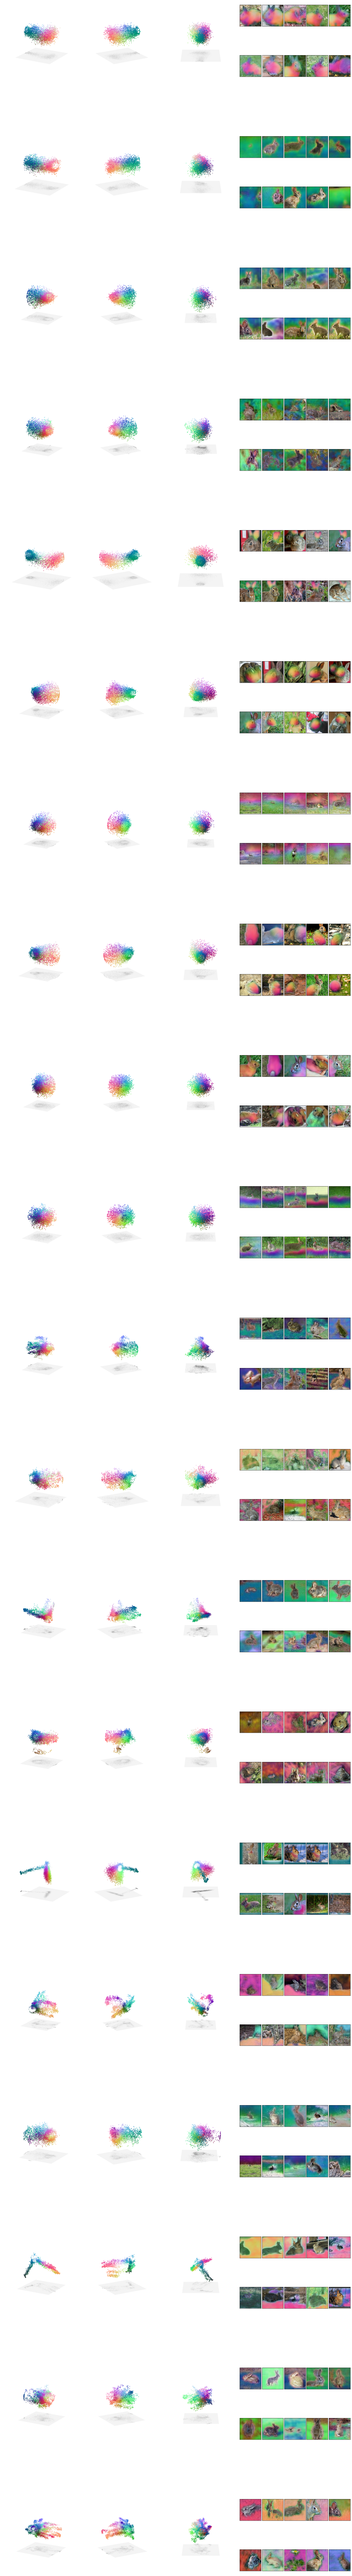

In [5]:
# One band per concept: left = 3D manifold (PCA of the contributions m_i, point
# uniform size, shadowed floor); right = a 2x5 grid of the images it fires hardest
# on, each patch tinted by its PCA->RGB coordinate (alpha = norm).
# per_axis_rgb=False normalises each PCA axis to full colour range; set False for
# one global scale centred at 0 (gray = zero, relative PC variance preserved).
bsf.viz.plot_concepts(z, atoms, images, top, grid, n_img=10, per_axis_rgb=False, point_size=4)
plt.show()